             Sales  Discount    Profit
Sales     1.000000 -0.028197  0.479067
Discount -0.028197  1.000000 -0.219481
Profit    0.479067 -0.219481  1.000000


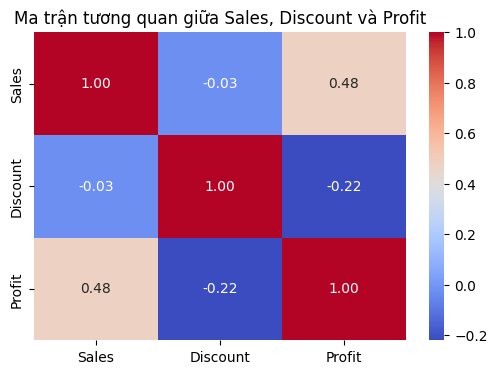

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu đã được làm sạch
df = pd.read_excel(r"C:\Users\ADMIN\Desktop\Đồ Án Kì\Datasets\Superstore Dataset Cleaned.xlsx")

# Xem nhanh hệ số tương quan
corr = df[['Sales', 'Discount', 'Profit']].corr()
print(corr)

# Vẽ heatmap để trực quan hóa
plt.figure(figsize=(6,4))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Ma trận tương quan giữa Sales, Discount và Profit")
plt.show()

In [17]:
import numpy as np

X = df[['Sales', 'Discount']].values
y = df['Profit'].values

# Thêm 1 cột giá trị 1 vào X để chứa hệ số chặn (Intercept, β0)
X_b = np.c_[np.ones((X.shape[0], 1)), X]  # ma trận [1, x1, x2]

In [18]:
# Tính toán beta theo công thức OLS
beta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)

beta_0, beta_1, beta_2 = beta
print("Intercept (β0):", beta_0)
print("Coefficient β1 (Sales):", beta_1)
print("Coefficient β2 (Discount):", beta_2)

Intercept (β0): 24.307821192402262
Coefficient β1 (Sales): 0.17788263156766623
Coefficient β2 (Discount): -233.90786701192192


In [19]:
# Dự đoán
y_pred = X_b.dot(beta)

# R^2
SS_res = np.sum((y - y_pred) ** 2)  # Residual Sum of Squares
SS_tot = np.sum((y - np.mean(y)) ** 2)  # Total Sum of Squares
R2 = 1 - (SS_res / SS_tot)

# MSE, RMSE
MSE = np.mean((y - y_pred) ** 2)
RMSE = np.sqrt(MSE)

print("R² Score:", R2)
print("MSE:", MSE)
print("RMSE:", RMSE)

R² Score: 0.2719634959386925
MSE: 39952.91945863461
RMSE: 199.88226399216768
